In [3]:
%pip install -q seaborn matplotlib

In [4]:
import os
import zipfile
import keras
import gdown
import mlflow

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image
from pathlib import Path



In [5]:
FILE_ID = '1PP09vNLPEsiFXFyKu4_8mC-bFJbxfflC' 

url = f'https://drive.google.com/uc?id={FILE_ID}'
zip_output = 'tumors_dataset.zip'
extract_dir = 'extract/'

try:
    if not os.path.exists(zip_output):
        gdown.download(url, zip_output, quiet=False)
    
    with zipfile.ZipFile(zip_output, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    
    data_path = Path(extract_dir)
    if (data_path / 'Data').exists():
        data_path = data_path / 'Data'
    elif (data_path / 'tumors' / 'Data').exists():
        data_path = data_path / 'tumors' / 'Data'

    print(f"Targeting data directory at: {data_path}")


except Exception as e:
    print(f"\n An error occurred: {e}")
    print("Please check your file ID, folder nesting inside the ZIP, or Drive permissions.")


Downloading...
From (original): https://drive.google.com/uc?id=1PP09vNLPEsiFXFyKu4_8mC-bFJbxfflC
From (redirected): https://drive.google.com/uc?id=1PP09vNLPEsiFXFyKu4_8mC-bFJbxfflC&confirm=t&uuid=afc0502d-d703-4998-8f08-8f6cceee13d6
To: /tumors_dataset.zip
100%|██████████| 156M/156M [00:18<00:00, 8.56MB/s] 


Targeting data directory at: extract/Data


In [6]:
# data_path = Path("/kaggle/input/datasets/ihmaditaha/tumors/Data")

image_count = len(list(data_path.glob('*/*.jpg')))
print(image_count)

7023


In [7]:
batch_size = 32
img_height = 224
img_width = 224
img_channels=3
AUTOTUNE = tf.data.AUTOTUNE
print("Num GPUs Available:", len(tf.config.list_physical_devices("GPU")))

Num GPUs Available: 1


In [8]:
list_ds = tf.data.Dataset.list_files(str(data_path/'*/*'), shuffle=False)
list_ds = list_ds.shuffle(image_count, reshuffle_each_iteration=False)

I0000 00:00:1792765104.525150    6607 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10259 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6


In [9]:
class_names = np.array(sorted([item.name for item in data_path.glob('*')]))
print(class_names)
num_classes = len(class_names)

['glioma' 'meningioma' 'notumor' 'pituitary']


In [10]:
test_size = int(image_count * 0.1)
temp_ds = list_ds.skip(test_size)
test_ds = list_ds.take(test_size)
train_ds = temp_ds.skip(test_size)
val_ds = temp_ds.take(test_size)

In [11]:
print(tf.data.experimental.cardinality(train_ds).numpy())
print(tf.data.experimental.cardinality(val_ds).numpy())
print(tf.data.experimental.cardinality(test_ds).numpy())

5619
702
702


In [12]:
def get_label(file_path):
  parts = tf.strings.split(file_path, os.path.sep)
  one_hot = parts[-2] == class_names
  return one_hot

def decode_img(img):
  img = tf.io.decode_jpeg(img, channels=3)
  return tf.image.resize(img, [img_height, img_width])

def process_path(file_path):
  label = get_label(file_path)
  img = tf.io.read_file(file_path)
  img = decode_img(img)
  return img, label

In [13]:
train_ds = train_ds.map(process_path, num_parallel_calls=AUTOTUNE)
val_ds = val_ds.map(process_path, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.map(process_path, num_parallel_calls=AUTOTUNE)

In [14]:
for image, label in train_ds.take(1):
  print("Image shape: ", image.numpy().shape)
  print("Label: ", label.numpy())

Image shape:  (224, 224, 3)
Label:  [ True False False False]


2026-10-23 14:18:27.121569: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [15]:
data_augmentation = tf.keras.Sequential([
  keras.layers.RandomFlip("horizontal_and_vertical"),
  keras.layers.RandomRotation(0.2),
],name="Data_augmentation")

In [16]:
rescale_layer = tf.keras.layers.Rescaling(1./127.5, offset=-1)

In [17]:
def prepare(ds, shuffle=False):
  ds = ds.cache()
  if shuffle:
    ds = ds.shuffle(1000)

  ds = ds.map(lambda x, y: (rescale_layer(x), y))
  ds = ds.batch(batch_size)
  ds = ds.prefetch(buffer_size=AUTOTUNE)

  return ds

train_ds = prepare(train_ds, shuffle=True)
val_ds = prepare(val_ds)
test_ds = prepare(test_ds)

2026-10-23 14:18:29.260766: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_15}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-10-23 14:18:29.260791: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node Data_augmentation_1/random_rotation_1/Add/_10}}]]
	 [[GroupCrossDeviceControlEdges_0/NoOp/_15]] [type.googleapis.com/tensorflow.DerivedStatus='']
2026-10-23 14:18:29.260797: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 717938712678457666
2026-10-23 14:18:29.260803: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 751472839885286198
2026-10-23 14:18:29.260816: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key has

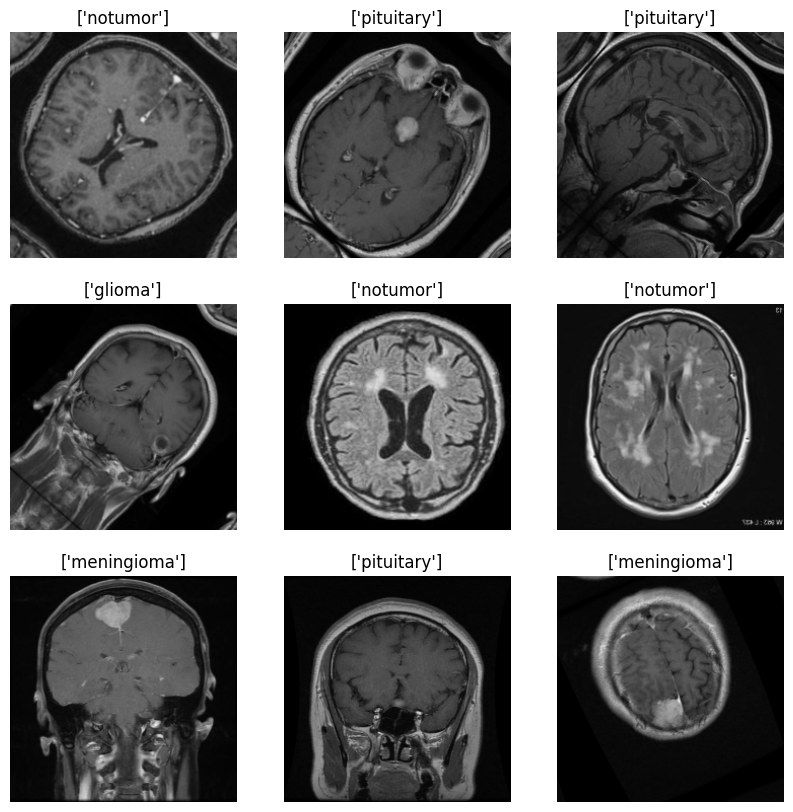

In [18]:
image_batch, label_batch = next(iter(train_ds))

plt.figure(figsize=(10, 10))
for i in range(9):
  ax = plt.subplot(3, 3, i + 1)
  plt.imshow((image_batch[i] + 1.0) / 2.0)
  label = label_batch[i]
  plt.title(class_names[label])
  plt.axis("off")

In [19]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(weights = "imagenet",include_top = False, input_shape = (img_height, img_width, img_channels))

base_model.trainable = False

model = tf.keras.Sequential([
  base_model,
  tf.keras.layers.GlobalAveragePooling2D(name="flatten1"),
  tf.keras.layers.Dense(128, activation='relu',name="FC1"),
  tf.keras.layers.Dropout(0.1),
  tf.keras.layers.Dense(num_classes,activation='softmax',name="FC2")
],name="cnn_model")
model.summary(show_trainable=True)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "cnn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ flatten1                    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ FC1 (Dense)                 │ (None, 128)           │    163,968 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 128)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ FC2 (Dense)                 │ (None, 4)             │        516 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
model.compile(
  optimizer=keras.optimizers.Adam(learning_rate=0.0001),
  loss='categorical_crossentropy',
  metrics=['accuracy'])

In [21]:
cllbcks = [
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
    keras.callbacks.ModelCheckpoint(filepath='./home/user/project/models/TL/best_TL_model.keras',save_best_only=True),
    keras.callbacks.BackupAndRestore("./home/user/Sync/TL/backup/", save_freq="epoch"),
    keras.callbacks.EarlyStopping(patience=3)
    ]
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=30,
  callbacks=cllbcks
)

Epoch 1/30


I0000 00:00:1792765117.618600    6672 service.cc:152] XLA service 0x73e064007e70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792765117.618621    6672 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 3060, Compute Capability 8.6
2026-10-23 14:18:37.754487: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792765118.506046    6672 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-10-23 14:18:39.256610: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1514', 204 bytes spill stores, 204 bytes spill loads

2026-10-23 14:18:39.709170: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_151

  4/176 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.2884 - loss: 1.5334  

I0000 00:00:1792765127.232102    6672 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.5849 - loss: 0.9848

2026-10-23 14:19:00.934274: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1514', 220 bytes spill stores, 220 bytes spill loads

2026-10-23 14:19:00.992378: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1514_0', 444 bytes spill stores, 1384 bytes spill loads

2026-10-23 14:19:01.484441: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1514', 8 bytes spill stores, 8 bytes spill loads

2026-10-23 14:19:01.948823: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1514', 5524 bytes spill stores, 5564 bytes spill loads

2026-10-23 14:19:02.425345: I e

176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.5856 - loss: 0.9834

2026-10-23 14:19:09.602702: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1165', 4 bytes spill stores, 4 bytes spill loads

2026-10-23 14:19:12.405707: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1158', 220 bytes spill stores, 220 bytes spill loads

2026-10-23 14:19:13.084012: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1158_0', 444 bytes spill stores, 1384 bytes spill loads

2026-10-23 14:19:13.206340: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1158', 5388 bytes spill stores, 5392 bytes spill loads

2026-10-23 14:19:13.580373: I e

176/176 ━━━━━━━━━━━━━━━━━━━━ 45s 181ms/step - accuracy: 0.5864 - loss: 0.9820 - val_accuracy: 0.8276 - val_loss: 0.5064 - learning_rate: 1.0000e-04
Epoch 2/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.8213 - loss: 0.4614 - val_accuracy: 0.8305 - val_loss: 0.4370 - learning_rate: 1.0000e-04
Epoch 3/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 68ms/step - accuracy: 0.8540 - loss: 0.3834 - val_accuracy: 0.8205 - val_loss: 0.4240 - learning_rate: 1.0000e-04
Epoch 4/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 71ms/step - accuracy: 0.8661 - loss: 0.3584 - val_accuracy: 0.8462 - val_loss: 0.3748 - learning_rate: 1.0000e-04
Epoch 5/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 70ms/step - accuracy: 0.8804 - loss: 0.3177 - val_accuracy: 0.8519 - val_loss: 0.3653 - learning_rate: 1.0000e-04
Epoch 6/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 68ms/step - accuracy: 0.8796 - loss: 0.3056 - val_accuracy: 0.8818 - val_loss: 0.3380 - learning_rate: 1.0000e-04
Epoch 7/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 71ms/step - accura

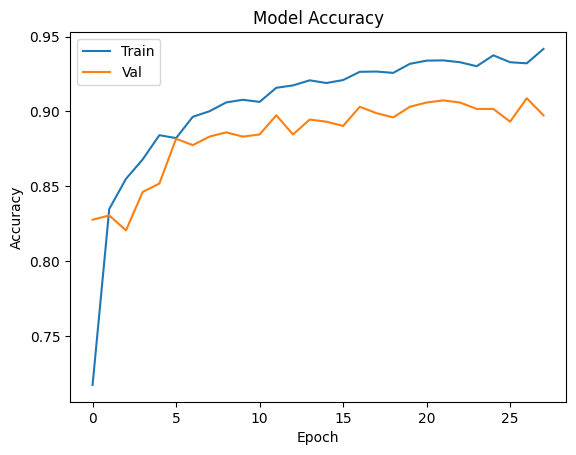

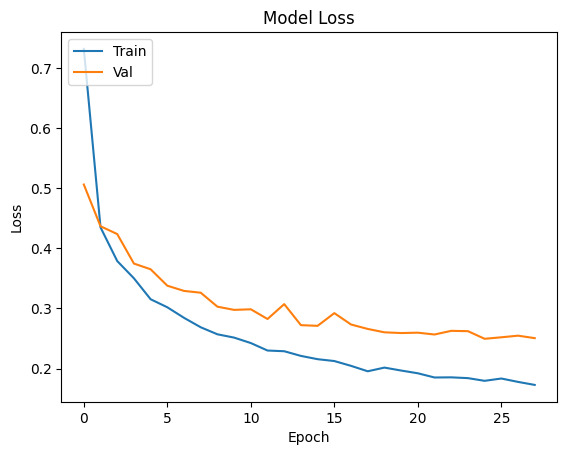

In [22]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Val'], loc='upper left')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Val'], loc='upper left')
plt.show()

In [23]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False
model.summary(show_trainable=True)

Model: "cnn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   Y   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ flatten1                    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ FC1 (Dense)                 │ (None, 128)           │    163,968 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 128)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ FC2 (Dense)                 │ (None, 4)             │        516 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,751,438 (10.50 MB)

 Trainable params: 1,370,564 (5.23 MB)

 Non-trainable params: 1,051,904 (4.01 MB)

 Optimizer params: 328,970 (1.25 MB)

In [24]:
model.compile(
  optimizer=keras.optimizers.Adam(learning_rate=1e-5),
  loss='categorical_crossentropy',
  metrics=['accuracy'])


In [25]:
cllbcks = [
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
    keras.callbacks.ModelCheckpoint(filepath='./home/user/project/models/FT/best_FT_model.keras',save_best_only=True),
    keras.callbacks.BackupAndRestore("./home/user/Sync/FT/backup/", save_freq="epoch"),
    keras.callbacks.EarlyStopping(patience=3)
    ]
fine_tune_history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=30,
  callbacks=cllbcks
)

Epoch 1/30
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8446 - loss: 0.4309

2026-10-23 14:25:26.220839: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6033', 12 bytes spill stores, 12 bytes spill loads



176/176 ━━━━━━━━━━━━━━━━━━━━ 35s 133ms/step - accuracy: 0.8449 - loss: 0.4302 - val_accuracy: 0.8860 - val_loss: 0.2905 - learning_rate: 1.0000e-05
Epoch 2/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.8860 - loss: 0.2974 - val_accuracy: 0.8960 - val_loss: 0.2795 - learning_rate: 1.0000e-05
Epoch 3/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.8987 - loss: 0.2677 - val_accuracy: 0.9046 - val_loss: 0.2668 - learning_rate: 1.0000e-05
Epoch 4/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.9123 - loss: 0.2405 - val_accuracy: 0.9074 - val_loss: 0.2573 - learning_rate: 1.0000e-05
Epoch 5/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 73ms/step - accuracy: 0.9147 - loss: 0.2164 - val_accuracy: 0.9103 - val_loss: 0.2418 - learning_rate: 1.0000e-05
Epoch 6/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.9287 - loss: 0.1889 - val_accuracy: 0.9188 - val_loss: 0.2333 - learning_rate: 1.0000e-05
Epoch 7/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accura

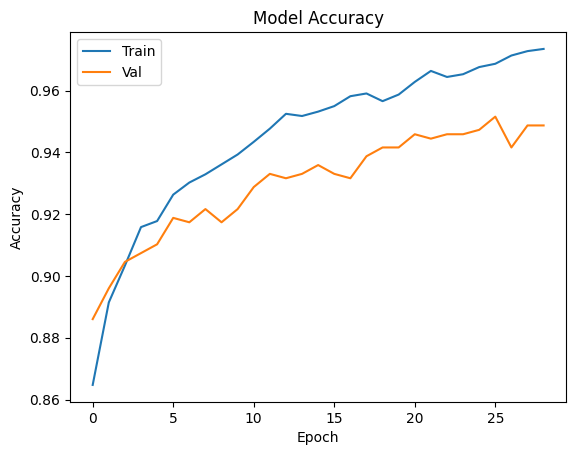

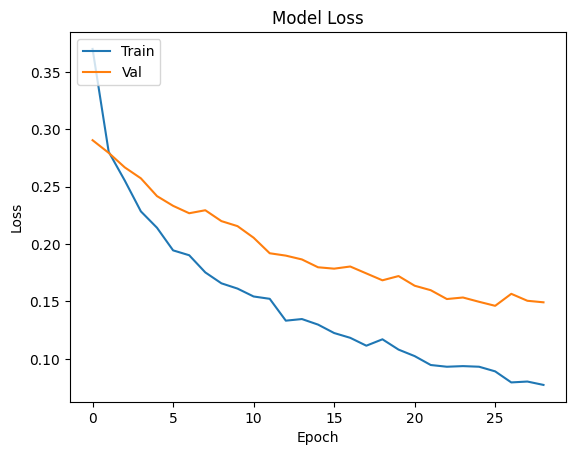

In [26]:
plt.plot(fine_tune_history.history['accuracy'])
plt.plot(fine_tune_history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Val'], loc='upper left')
plt.show()

plt.plot(fine_tune_history.history['loss'])
plt.plot(fine_tune_history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Val'], loc='upper left')
plt.show()

In [27]:
np.save("./home/user/Sync/TL/TL_history.npy", history.history)
np.save("./home/user/Sync/FT/FT_history.npy", fine_tune_history.history)
